SERIES DE VIAS AEREAS

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
from scipy.stats import boxcox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sktime.forecasting.naive import NaiveForecaster
from prophet import Prophet
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

Funciones a usar:

In [84]:
def estacionariedad_media(datos, alpha):#implementada por Ricardo Rodriguez
    adf = adfuller(datos, regression="c")[1]
    kpss_test = kpss(datos, regression="c", nlags="auto")[1]

    if adf < alpha:
        texto_1 = f'Prueba ADF: Se rechaza la hipótesis nula, ya que el valor p = {adf} < alpha = {alpha}. La serie es estacionaria en media.'
    else:
        texto_1 = f'Prueba ADF: No se rechaza la hipótesis nula, ya que el valor p = {adf} >= alpha = {alpha}. La serie se considera no estacionaria en media.'

    if kpss_test < alpha:
        texto_2 = f'Prueba KPSS: Se rechaza la hipótesis nula, ya que el valor p = {kpss_test} < alpha = {alpha}. La serie no es estacionaria en media.'
    else:
        texto_2 = f'Prueba KPSS: No se rechaza la hipótesis nula, ya que el valor p = {kpss_test} >= alpha = {alpha}. La serie se considera estacionaria en media.'

    print(texto_1)
    print(texto_2)

    if (adf <= alpha and kpss_test <= alpha) or (adf > alpha and kpss_test > alpha):
        print('Las pruebas no coinciden, pero se realizará diferenciación, ya que una muestra la no estacionariedad de la media.')

In [85]:
def estacionariedad_varianza(datos, alpha):#implementada por Ricardo Rodriguez
    arch = het_arch(datos)[1]

    if arch < alpha:
        texto_1 = f'Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = {arch} < alpha = {alpha}. La serie no es estacionaria en varianza. Se hará una transformación.'
    else:
        texto_1 = f'Prueba ARCH: No se rechaza la hipótesis nula, ya que el valor p = {arch} >= alpha = {alpha}. La serie se considera estacionaria en varianza.'

    print(texto_1)

In [86]:
# Función que evalúa las métricas. Implementada por Ricardo Rodriguez
def metricas(y_real, y_pred):
    return {'MAE': mean_absolute_error(y_real, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_real, y_pred))}

In [87]:
df = pd.read_csv("DATOS_LIMPIOS.csv")
df.head()

,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero,Fecha
0,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1.0,2009-01-01
1,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716.0,2009-01-01
2,Aérea,01 La Aurora,Angola,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA CENTRAL,08 OTROS,Resto del Mundo,Turista,4.0,2009-01-01
3,Aérea,01 La Aurora,Arabia Saudita,OTROS ORIENTE MEDIO,Oriente Medio,ORIENTE MEDIO,08 OTROS,Resto del Mundo,Turista,5.0,2009-01-01
4,Aérea,01 La Aurora,Argelia,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA DEL NORTE,08 OTROS,Resto del Mundo,Turista,1.0,2009-01-01


SERIE DE TIEMPO

In [88]:
df_filtro = df[df["Vía"] == "Aérea"]
df_fecha = df_filtro.groupby("Fecha")["Viajero"].sum().round(0).astype(int)

serie = df_fecha.to_frame("Aérea")
serie = serie.sort_values(by="Fecha", ascending=True)
serie.index = pd.to_datetime(serie.index)
serie.index = serie.index.to_period("M")

ESTIMACIÓN DE LA TENDENCIA DURANTE LA PANDEMIA

In [89]:
inicio = pd.Period('2020-03', freq='M')
fin = pd.Period('2022-12', freq='M')

In [90]:
y_train = serie.loc[serie.index < inicio, 'Aérea']
modelo = NaiveForecaster(strategy='last', sp=12)
modelo.fit(y_train)
fh = range(len(y_train) + 1, len(y_train) + len(pd.period_range(inicio, fin, freq='M')) + 1)
predicciones = modelo.predict(fh=fh)

# Reindexando si no existen
serie = serie.reindex(serie.index.union(pd.period_range(inicio, fin, freq='M')), fill_value=0)
serie.loc[inicio:fin, 'Aérea'] = predicciones.to_numpy()
serie['Aérea'] = serie['Aérea'].round().astype(int)
serie.index = serie.index.to_timestamp()

TRAIN Y TEST

In [91]:
filas, columnas = serie.shape
fil_train = int(filas * 0.7)
train = serie.iloc[:fil_train+1]
test = serie.iloc[fil_train+1:]

In [92]:
serie.head()

,Aérea
2009-01-01,81693
2009-02-01,70099
2009-03-01,84494
2009-04-01,80618
2009-05-01,64621


DESCOMPOSICIÓN DE LA SERIE TEMPORAL

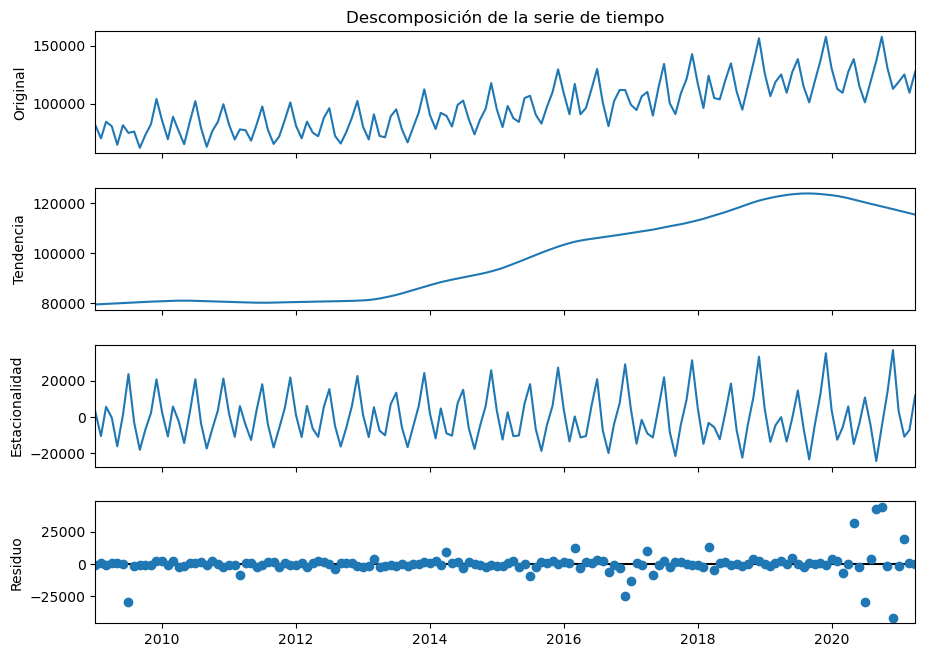

In [93]:
stl = STL(train, period=12, robust=True)

descomposicion = stl.fit()
fig = descomposicion.plot()
fig.set_size_inches(10, 7)
axes = fig.axes
axes[0].set_title('Descomposición de la serie de tiempo')
axes[0].set_ylabel('Original')
axes[1].set_ylabel('Tendencia')
axes[2].set_ylabel('Estacionalidad')
axes[3].set_ylabel('Residuo')
plt.show()

Valor alfa

In [94]:
alfa=0.05

VERIFICACIÓN DE ESTACIONARIEDAD EN MEDIA -- SERIE ORIGINAL

In [95]:
estacionariedad_media(serie, alfa)

Prueba ADF: No se rechaza la hipótesis nula, ya que el valor p = 0.4916334971747757 >= alpha = 0.05. La serie se considera no estacionaria en media.
Prueba KPSS: Se rechaza la hipótesis nula, ya que el valor p = 0.01 < alpha = 0.05. La serie no es estacionaria en media.


C:\Users\aripi\AppData\Local\Temp\ipykernel_17064\1481830582.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_test = kpss(datos, regression="c", nlags="auto")[1]


VERIFICACIÓN DE ESTACIONARIEDAD EN MEDIA -- SERIE DIFERENCIADA

In [96]:
estacionariedad_media(train.diff()[1:], alfa)

Prueba ADF: Se rechaza la hipótesis nula, ya que el valor p = 1.7465649424796965e-15 < alpha = 0.05. La serie es estacionaria en media.
Prueba KPSS: No se rechaza la hipótesis nula, ya que el valor p = 0.1 >= alpha = 0.05. La serie se considera estacionaria en media.


C:\Users\aripi\AppData\Local\Temp\ipykernel_17064\1481830582.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_test = kpss(datos, regression="c", nlags="auto")[1]


VERIFICACIÓN DE ESTACIONARIEDAD EN VARIANZA -- SERIE ORIGINAL

In [97]:
estacionariedad_varianza(train, alfa)

Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = 9.424527658192717e-17 < alpha = 0.05. La serie no es estacionaria en varianza. Se hará una transformación.


VERIFICACION DE ESTACIONARIEDAD EN VARIANZA -- SERIE BOX COX

In [98]:
train_box_cox, lambda_optimo = boxcox(train['Aérea'])
estacionariedad_varianza(train_box_cox, alfa)

Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = 7.035858125824228e-19 < alpha = 0.05. La serie no es estacionaria en varianza. Se hará una transformación.


Dado que aún después de aplicar Box Cox (el cuál se usa para estabilizar este parámetro) la serie sigue siendo no-estacionaria, se intuye que esta característica está arraigada a los datos y no es posible eliminarla de la misma.

TRANSFORMACIONES

In [99]:
trans_train=train

ELECCION DEL PARAMETRO d

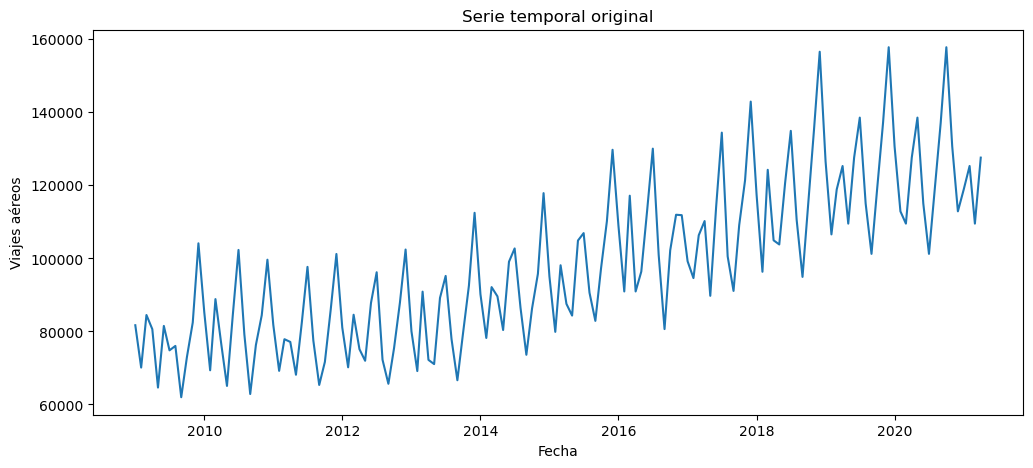

In [100]:
y=train
plt.figure(figsize=(12, 5))
plt.plot(y)
plt.title("Serie temporal original")
plt.xlabel("Fecha")
plt.ylabel("Viajes aéreos")
plt.show()

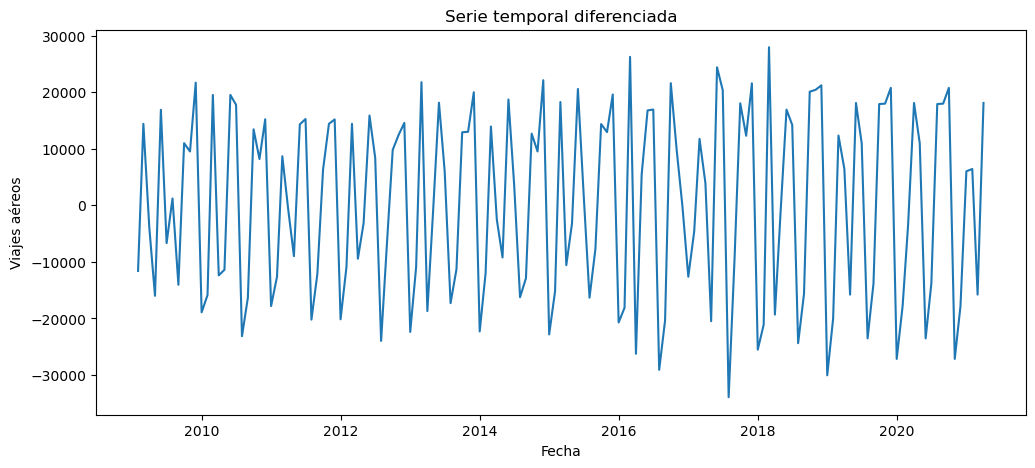

In [101]:
y = train.diff(1).dropna()
plt.figure(figsize=(12, 5))
plt.plot(y)
plt.title("Serie temporal diferenciada")
plt.xlabel("Fecha")
plt.ylabel("Viajes aéreos")
plt.show()

Es posible observar que se ha eliminado la tendencia creciente de la serie; la varianza se ha mediado ligeramente aunque aún es visible que esta no es estacionaria en cuanto a este parámetro, dada la poca uniformidad visible en los picos de la serie a lo largo del tiempo estudiado.

ELECCIÓN DE LOS PARÁMETROS p & q

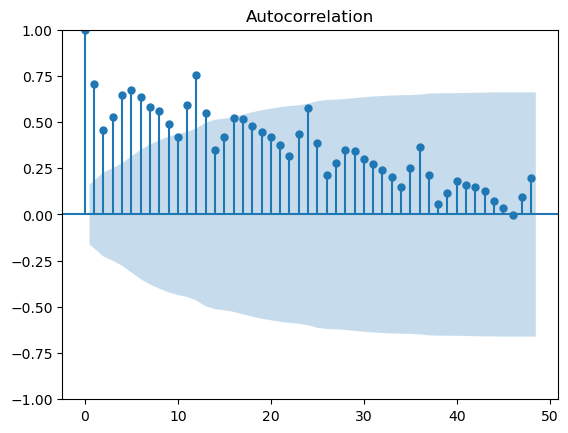

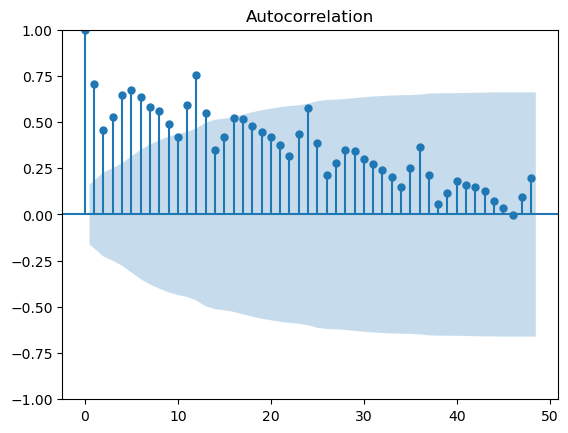

In [102]:
plot_acf(trans_train, lags=48)


Se observa que la autocorrelación cae abruptamente antes de 10; después de este valor del retraso, se observa que los residuos llegan a estabilizarse ligeramente, a excepción de un pico que aparece cercano a 11.

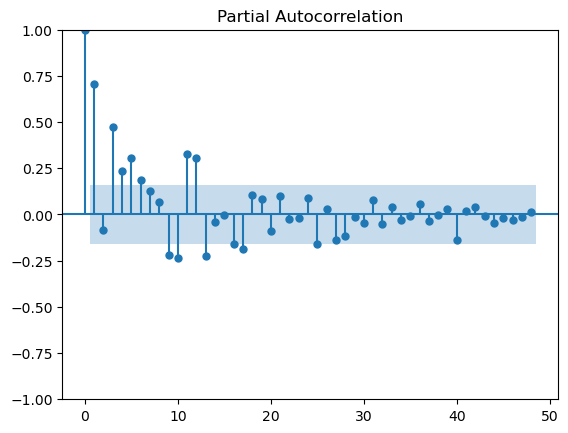

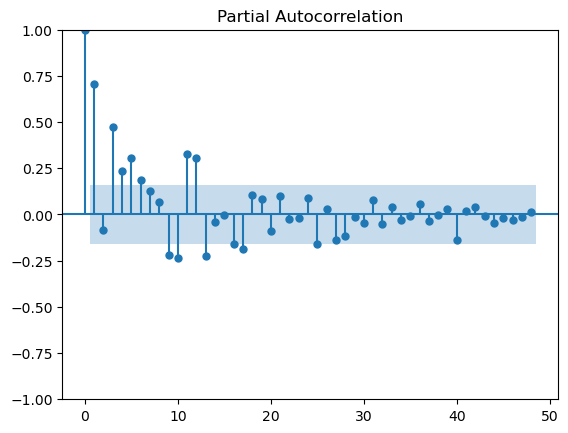

In [103]:
plot_pacf(trans_train, lags=48)

PACF también cae abruptamente en el cuarto retraso, mas vuelve a elevarse ligeramente en el 9 y 13; también se percibe una caída abajo de los límites en los retrasos 15 y 16.

ELECCIÓN DE PARÁMETRO D

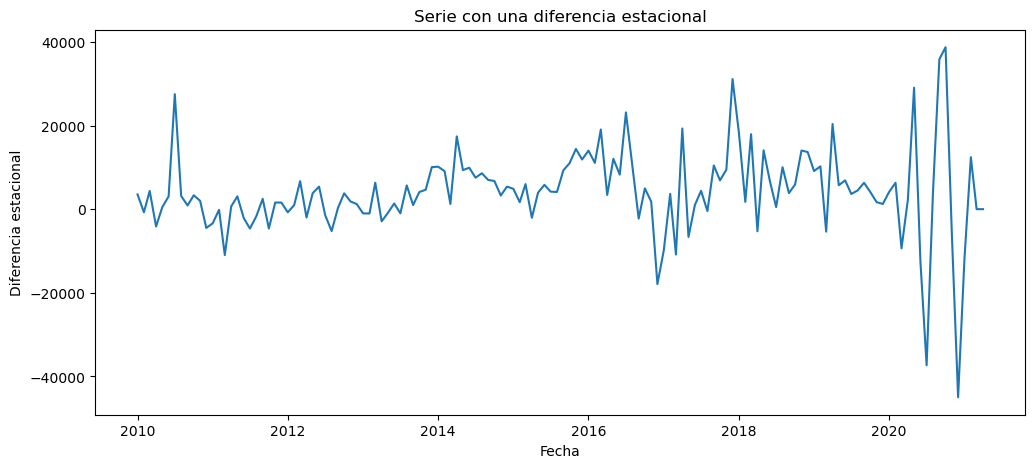

In [104]:
m = 12

y_diff_estacional = train.diff(12)

plt.figure(figsize=(12, 5))
plt.plot(y_diff_estacional)
plt.title("Serie con una diferencia estacional")
plt.xlabel("Fecha")
plt.ylabel("Diferencia estacional")
plt.show()

Se observa cierta setabilidad respecto a la media.

ELECCIÓN DE LOS PARÁMETROS P & Q

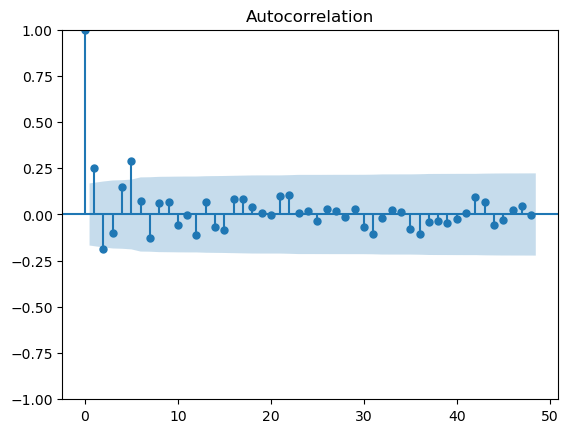

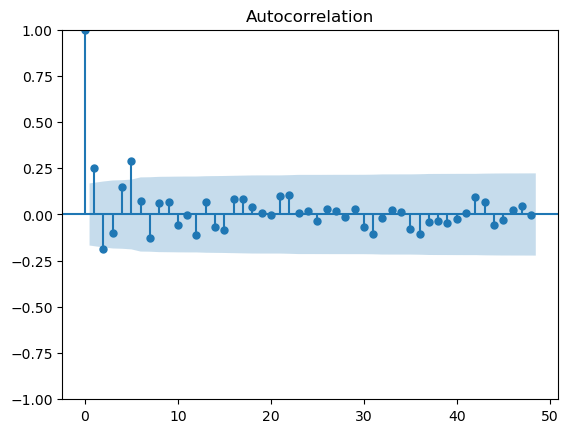

In [105]:
plot_acf(train.diff(12).dropna(), lags=48)

Se observa que ACF cae en el primer retraso

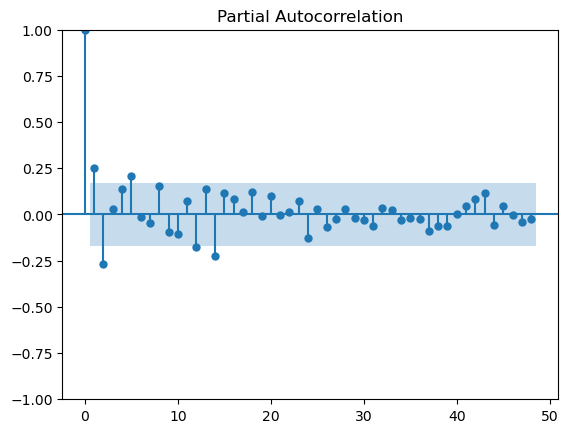

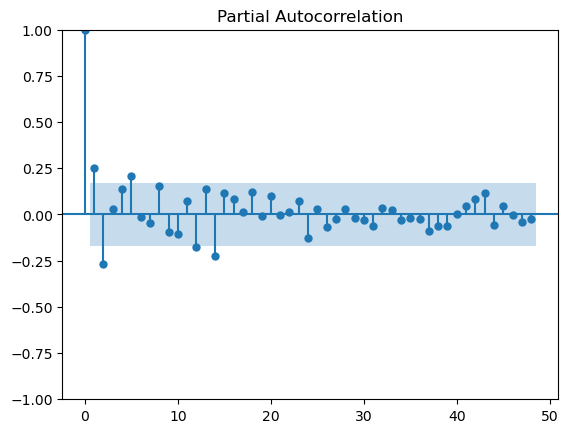

In [106]:
plot_pacf(train.diff(12).dropna(), lags=48)

En este caso, PACF cae igualmente en el primer retraso.

ELECCIÓN DE PARÁMETROS

**$d=1$**: Tras la primera diferenciación se llegó a apreciar cierta estacionalidad respecto a la media.

**$p=1$**: La abrupta caida en el primer retraso del PACF hace que llegue al umbral de 0.25.


**$q=7$**: Llega al umbral de 0.25 a los cuatro retrasos en ACF


**$D=1$**: Dado que se ha estabilizado tras la primera diferenciación.


**$P=0$**: Se observa que el retraso 1 no es significativo en el PACF.


**$Q=0$**: Se observa que el retraso 1 no es significativo en el ACF.

ENTRENAMIENTO DE MODELOS **SARIMA**

In [137]:
modelo_1 = SARIMAX(trans_train, order=(1, 7, 1), seasonal_order=(0, 1, 0, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_1 = modelo_1.fit(maxiter=500, disp=False)

In [138]:
modelo_2 = SARIMAX(trans_train, order=(2, 1, 0), seasonal_order=(0, 1, 0, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_2 = modelo_2.fit(maxiter=500, disp=False)

In [139]:
modelo_3 = SARIMAX(trans_train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_3 = modelo_3.fit(maxiter=500, disp=False)

COMPARACIÓN DE MODELOS

In [140]:
modelos = {"SARIMA 1": sarima_1, "SARIMA 2": sarima_2, "SARIMA 3": sarima_3}

resultados = []

for nombre, modelo in modelos.items():
    residuos = modelo.resid.dropna()

    ljung_box = acorr_ljungbox(residuos, lags=[12], return_df=True)
    resultados.append({"Modelo": nombre, "AIC": modelo.aic, "BIC": modelo.bic, "Media residuos": residuos.mean(), 
                       "Ljung-Box p-value": ljung_box["lb_pvalue"].iloc[0]})

comparacion = pd.DataFrame(resultados).sort_values(by=["AIC", "BIC"])

print(comparacion)

     Modelo          AIC          BIC  Media residuos  Ljung-Box p-value
2  SARIMA 3  2590.816856  2604.795809    -2083.362778       2.174813e-02
1  SARIMA 2  2867.916550  2876.587598       90.080624       7.248635e-05
0  SARIMA 1  3393.453471  3401.986032   -64625.418790       2.333415e-44


Se procede a la elección del modelo SARIMA 3 ya que tanto AIC como BIC son menores que en los otros dos modelos. Se observa que todos los valores p son menores a 0.05, razón por la que cumplen con la independencia de los residuos.

OTROS MODELOS

In [141]:
# Período de predicción.
periodo_estacional = 12
predicciones = {}
# Métricas de los modelos SARIMA
modelos_sarima = {
    'SARIMA 1': sarima_1,
    'SARIMA 2': sarima_2,
    'SARIMA 3': sarima_3
}

for nombre, modelo in modelos_sarima.items():
    predicciones[nombre] = modelo.forecast(steps=len(test))

In [142]:
# Prophet
prophet_train = pd.DataFrame({'ds': trans_train.index,
                              'y': trans_train['Aérea']})

modelo_prophet = Prophet()
modelo_prophet.fit(prophet_train)
futuro = pd.DataFrame({'ds': test.index})
predicciones['Prophet'] = modelo_prophet.predict(futuro)['yhat'].values

13:17:21 - cmdstanpy - INFO - Chain [1] start processing
13:17:22 - cmdstanpy - INFO - Chain [1] done processing


In [143]:
# Holt-Winters
modelo_hw = ExponentialSmoothing(trans_train, trend="add", seasonal="add", seasonal_periods=periodo_estacional).fit()
predicciones["Holt-Winters"] = modelo_hw.forecast(len(test))

In [144]:
# Suavizamiento exponencial simple
modelo_ses = SimpleExpSmoothing(trans_train).fit(optimized=True)
predicciones["Suavizamiento exponencial"] = modelo_ses.forecast(len(test))

In [145]:
# Seasonal Naive
predicciones["Seasonal Naive"] = np.resize(trans_train.iloc[-periodo_estacional:].values, len(test))

In [146]:
# Comparación
resultados = []

for nombre, prediccion in predicciones.items():
    valores = metricas(prueba.values, np.asarray(prediccion))

    resultados.append({
        "Modelo": nombre,
        "MAE": valores["MAE"],
        "RMSE": valores["RMSE"],
        "AIC": modelos_sarima[nombre].aic
        if nombre in modelos_sarima else np.nan,
        "BIC": modelos_sarima[nombre].bic
        if nombre in modelos_sarima else np.nan
    })

comparacion = pd.DataFrame(resultados).sort_values("RMSE")

print(comparacion)
print("\nMejor modelo:", comparacion.iloc[0]["Modelo"])

                      Modelo           MAE          RMSE          AIC  \
5  Suavizamiento exponencial  1.235714e+05  1.235714e+05          NaN   
6             Seasonal Naive  1.244842e+05  1.253311e+05          NaN   
2                   SARIMA 3  1.282969e+05  1.286522e+05  2590.816856   
1                   SARIMA 2  1.340039e+05  1.349068e+05  2867.916550   
4               Holt-Winters  1.367005e+05  1.372289e+05          NaN   
3                    Prophet  1.458132e+05  1.464190e+05          NaN   
0                   SARIMA 1  7.928506e+11  1.508851e+12  3393.453471   

           BIC  
5          NaN  
6          NaN  
2  2604.795809  
1  2876.587598  
4          NaN  
3          NaN  
0  3401.986032  

Mejor modelo: Suavizamiento exponencial


ELECCION DEL MEJOR MODELO

In [147]:
# Predicción del mejor modelo
indice = 0
mejor_modelo_nombre = comparacion.iloc[indice]["Modelo"]
print('Se selecciona el modelo:', mejor_modelo_nombre)
mejor_modelo = sarima_1

Se selecciona el modelo: Suavizamiento exponencial


GRÁFICA DE PREDICCIÓN

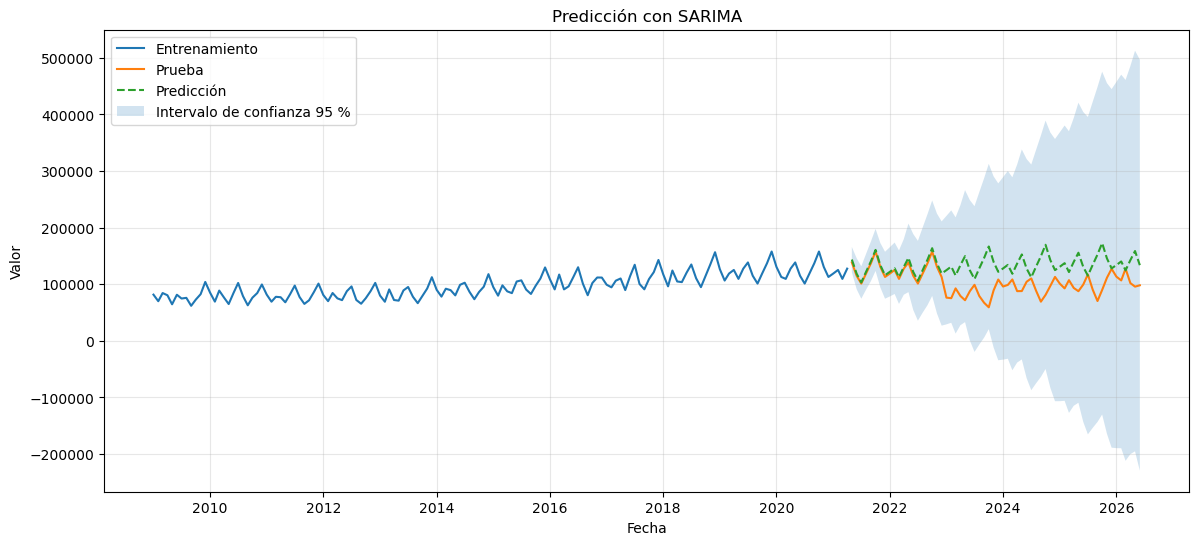

In [148]:
# Predicción e intervalos de confianza
pronostico_sarima = sarima_2.get_forecast(steps=len(test))
prediccion_sarima = pronostico_sarima.predicted_mean
intervalos = pronostico_sarima.conf_int(alpha=0.05)

limite_inferior = intervalos.iloc[:, 0]
limite_superior = intervalos.iloc[:, 1]

# Ajustar el índice al conjunto de prueba
prediccion_sarima.index = test.index
limite_inferior.index = test.index
limite_superior.index = test.index

# Gráfica
plt.figure(figsize=(14, 6))
plt.plot(train.index, train, label="Entrenamiento")
plt.plot(test.index, test, label="Prueba")
plt.plot(test.index, prediccion_sarima, linestyle="--", label="Predicción")
plt.fill_between(test.index, limite_inferior, limite_superior, alpha=0.2, label="Intervalo de confianza 95 %")
plt.title("Predicción con SARIMA")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

El modelo SARIMA 2, ha logrado seguir la tendencia solo hasta fechas cercanas al 2023, ya que después hay una caída sin precedente en los datos que provoca que el modelo no pueda predecirlo correctamente.